# 04 — Competitive Analysis (Fixed)

Loads pre-computed competitive features and explores the dataset landscape.

In [1]:
import sys
import os
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings('ignore')

sys.path.insert(0, '..')
os.makedirs('../data/figures', exist_ok=True)

print('Imports OK')

Imports OK


In [2]:
# Load competitive features
features_path = '../data/features/competitive_features.csv'

if os.path.exists(features_path):
    cf = pd.read_csv(features_path)
    print(f'Loaded: {cf.shape[0]:,} rows × {cf.shape[1]} columns')
    print(f'\nColumns: {list(cf.columns)}')
else:
    raise FileNotFoundError(f'{features_path} not found')

Loaded: 33,869 rows × 57 columns

Columns: ['product_id', 'merchant', 'observed_at', 'price', 'price_min', 'price_max', 'is_sale', 'availability', 'condition', 'offer', 'product_name', 'brand', 'manufacturer', 'manufacturer_number', 'category', 'source_url', 'observation_index', 'previous_price', 'absolute_change', 'percentage_change', 'days_since_previous', 'log_price', 'log_price_diff', 'expanding_zscore', 'price_direction', 'cumulative_log_change', 'rolling_mean_3', 'rolling_std_3', 'rolling_median_3', 'rolling_mean_price_3', 'rolling_volatility_3', 'price_deviation_3', 'rolling_mean_5', 'rolling_std_5', 'rolling_median_5', 'rolling_mean_price_5', 'rolling_volatility_5', 'price_deviation_5', 'rolling_mean_10', 'rolling_std_10', 'rolling_median_10', 'rolling_mean_price_10', 'rolling_volatility_10', 'price_deviation_10', 'competitor_count', 'competitor_price_min', 'competitor_price_max', 'competitor_price_mean', 'competitor_price_median', 'price_vs_comp_median', 'price_vs_comp_mean', 

Top-15 products by merchant coverage:
                product_id  merchant_count
1091  AVwjvtCJQMlgsOJE8qvf              18
1140  AVzdLh75GV-KLJ3aba9I              18
384   AVpfHjh7LJeJML432w1s              19
64    AV1YCmVn-jtxr-f31MZv              19
170   AV1l_SP5vKc47QAVhnZj              20
66    AV1YDFytvKc47QAVgpa2              20
147   AV1YIShaGV-KLJ3addRb              21
67    AV1YDIi6vKc47QAVgpcL              23
61    AV1YCcwVGV-KLJ3adb_T              24
721   AVpgoUa4LJeJML43Qomn              25
63    AV1YCh1FvKc47QAVgpNt              28
803   AVphcCmRLJeJML43a6Mh              29
441   AVpfTLmH1cnluZ0-iHRH              58
918   AVpjV8a21cnluZ0-VtTJ              60
62    AV1YCe4G-jtxr-f31MVO              79


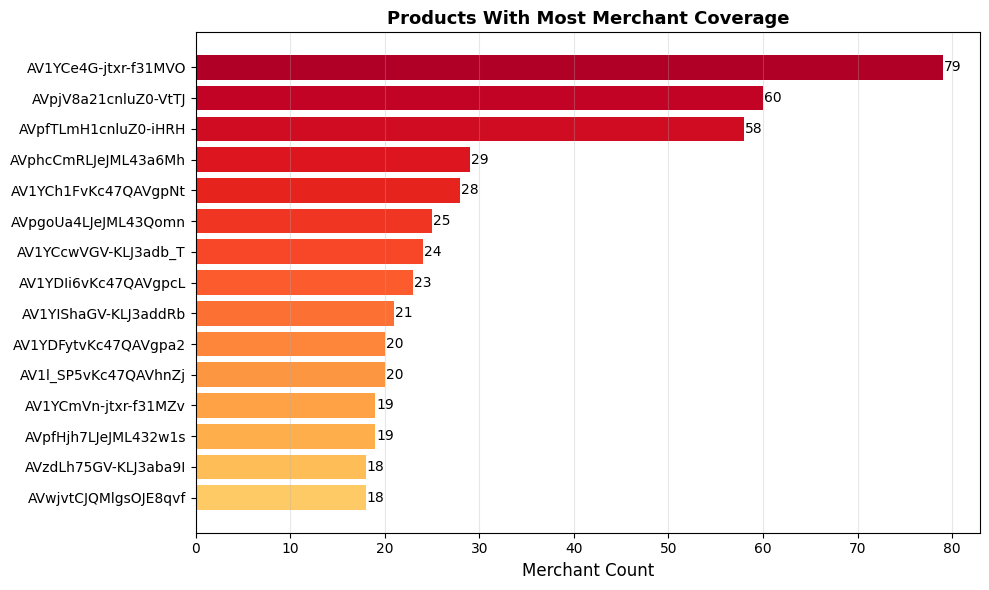

Saved: products_most_competitors.png


In [3]:
# Products with most merchant coverage
max_competitors = (
    cf
    .groupby('product_id')['merchant']
    .nunique()
    .rename('merchant_count')
    .reset_index()
    .nlargest(15, 'merchant_count')
    .sort_values('merchant_count', ascending=True)
)

print(f'Top-15 products by merchant coverage:')
print(max_competitors.to_string())

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.YlOrRd(np.linspace(0.3, 0.9, len(max_competitors)))
bars = ax.barh(
    [str(x)[:35] for x in max_competitors['product_id']],
    max_competitors['merchant_count'],
    color=colors
)
ax.set_xlabel('Merchant Count', fontsize=12)
ax.set_title('Products With Most Merchant Coverage', fontsize=13, fontweight='bold')
for bar, val in zip(bars, max_competitors['merchant_count']):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2, str(int(val)), va='center')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../data/figures/products_most_competitors.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved: products_most_competitors.png')

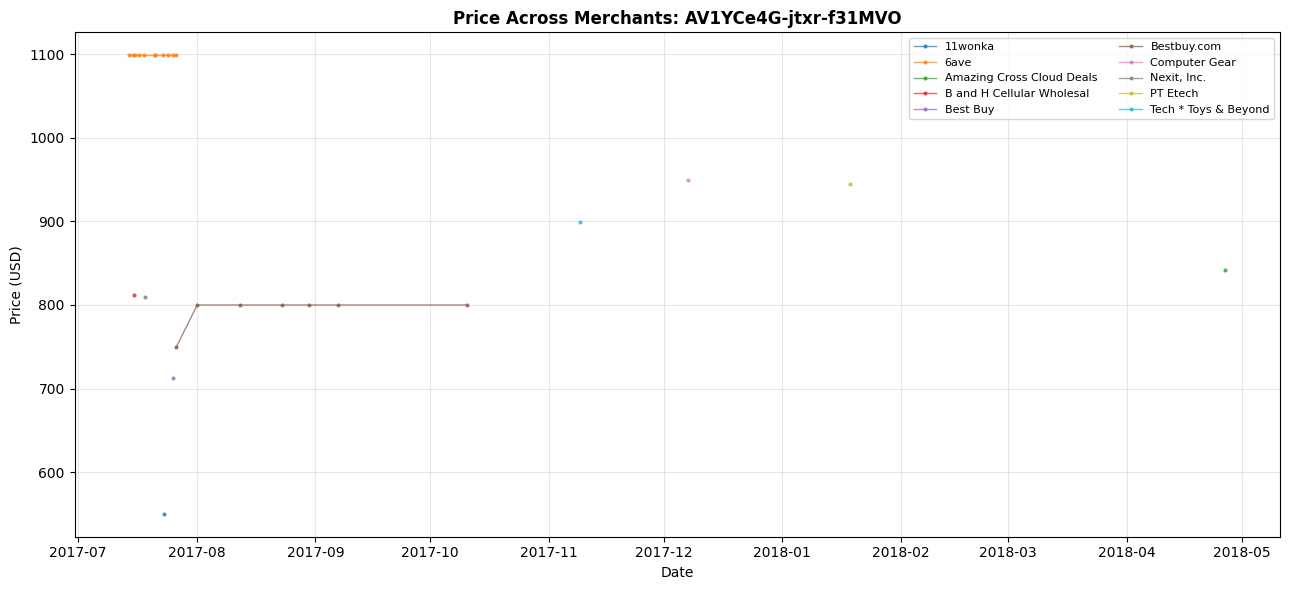

Saved: multi_merchant_price_history.png


In [4]:
# Multi-merchant price history
merchant_counts = cf.groupby('product_id')['merchant'].nunique()
sample_pid = merchant_counts.idxmax()
product_data = cf[cf['product_id'] == sample_pid].copy()
product_data['observed_at'] = pd.to_datetime(product_data['observed_at'])

fig, ax = plt.subplots(figsize=(13, 6))
merchants_in_product = product_data['merchant'].unique()[:10]  # Limit to 10 for readability

for idx, m in enumerate(merchants_in_product):
    m_data = product_data[product_data['merchant'] == m].sort_values('observed_at')
    ax.plot(m_data['observed_at'], m_data['price'], marker='o', markersize=2, linewidth=1, label=str(m)[:25], alpha=0.7)

ax.set_title(f'Price Across Merchants: {str(sample_pid)[:50]}', fontsize=12, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Price (USD)')
ax.legend(fontsize=8, loc='best', ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../data/figures/multi_merchant_price_history.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved: multi_merchant_price_history.png')

In [5]:
# Summary stats
print('\n=== Dataset Summary ===')
print(f'Total observations: {len(cf):,}')
print(f'Unique products: {cf["product_id"].nunique():,}')
print(f'Unique merchants: {cf["merchant"].nunique():,}')
print(f'Date range: {cf["observed_at"].min()} to {cf["observed_at"].max()}')

print('\n=== Price Statistics ===')
print(cf['price'].describe().to_string())

# Distribution by merchant
top_merchants = cf['merchant'].value_counts().head(10)
print('\n=== Top 10 Merchants by Observation Count ===')
print(top_merchants.to_string())


=== Dataset Summary ===
Total observations: 33,869
Unique products: 1,245
Unique merchants: 1,536
Date range: 2014-08-30 16:00:00+00:00 to 2018-07-25 23:00:00+00:00

=== Price Statistics ===
count    33869.000000
mean       529.578146
std       1177.658928
min          1.000000
25%         83.350000
50%        199.000000
75%        499.000000
max      26871.000000

=== Top 10 Merchants by Observation Count ===
merchant
Bestbuy.com         14023
bhphotovideo.com     7929
Walmart.com          2089
Amazon.com           1008
Beach Camera          492
buydig                243
Best Buy              164
LG.com                153
Focus Camera          146
AMI Ventures Inc      129
